# Chile: RAN 21-13 Annex 1 on a CLP and UF balance sheet

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- explain why the Chilean regulator treats the UF as a currency of its own (the UR) with its own curve, shock sizes, floor and charge, and read the two legs of a CLP and UF balance sheet;
- rebuild the curves of the two legs from the observed yields with the engine, and say what the peso curve lacks;
- compute the delta EVE of each leg under the six shocks, combine the two legs with the 50 percent offset rule, and obtain the Annex 1 delta EVE;
- compute the delta NII of each leg, add the indexation charge, and obtain the Annex 1 delta NII;
- apply the three tests that make a bank prioritised, and read the distance of every post-shock rate to its floor;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C15: **Banco Andino**, a **synthetic** bank with a balance sheet in Chilean pesos (CLP) and in UF (the Chilean inflation-indexed unit of account, CLF), at the valuation date 2026-09-03. Its aggregates are calibrated to the system figures of the CMF's August 2026 report (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, the Chilean regulator, public statistics of the licence class `mirror-allowed`); the UF share, the repricing profile of each item, the deposit split and every behavioural assumption are synthetic and stated in the document. The **curves are real**: the yields of the Banco Central de Chile (BDE table F022, `mirror-allowed`, attribution "Fuente: Banco Central de Chile, Base de Datos Estadísticos") and the value of the UF of the date (series F073.UFF.PRE.Z.D). Money is in CLP millions; the UF leg is in CLF millions and is converted with the UF value only where the two legs are added. The engine never converts between currencies.

The case commits six variants of the same bank, each a different stress on the book: `short-uf` (net short in UF at 30 percent of Tier 1), `long-uf` (net long), `cpi-surprise` (net long, with an inflation surprise of 2.5 points), `clp-steepener` (a longer peso book), `offset-on-off` (the offset rule compared with and without) and `floors-active` (70 percent of the UF commercial loans floating, to bring the floors into play).

- **Files read:** `data/derived/C15/short-uf.json`, `long-uf.json`, `cpi-surprise.json`, `clp-steepener.json`, `offset-on-off.json` and `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `cpi_scenario`, `thresholds`; `tests`; `impact`) and `models-banco-andino-2026-09.json` (`fit.annex1_table`, `multipliers`, `nmd_caps`, `buckets`).

The next cell loads the seven files and prints the engine version that baked them.

In [2]:
# Load the six variants and the model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C15"
ids = ["short-uf", "long-uf", "cpi-surprise", "clp-steepener", "offset-on-off", "floors-active"]
variants = {v: json.loads((derived / f"{v}.json").read_text(encoding="utf-8")) for v in ids}
fit = json.loads((derived / "models-banco-andino-2026-09.json").read_text(encoding="utf-8"))["fit"]
out = variants["short-uf"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener",
        "flattener": "flattener", "short-up": "short up", "short-down": "short down",
        "delta-eve": "delta EVE", "delta-nii": "delta NII", "on": "on", "off": "off", "compared": "compared",
        True: "yes", False: "no"}

print(out["bank"]["notice"][LANG])
for v, d in variants.items():
    print(f"{v:14s} | baked by riskvalidation {d['provenance']['riskvalidation_version']} | installed {rv.__version__}")

Banco Andino is a synthetic bank. Its balance-sheet aggregates are calibrated to the CMF system aggregates of August 2026; the UF share, the repricing profile of each item, the deposit split and every behavioural assumption are synthetic and stated in the document. The curves are real: the Banco Central de Chile F022 yields of the valuation date.
short-uf       | baked by riskvalidation 0.9.0 | installed 0.9.0
long-uf        | baked by riskvalidation 0.9.0 | installed 0.9.0
cpi-surprise   | baked by riskvalidation 0.9.0 | installed 0.9.0
clp-steepener  | baked by riskvalidation 0.9.0 | installed 0.9.0
offset-on-off  | baked by riskvalidation 0.9.0 | installed 0.9.0
floors-active  | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

Annex 1 of chapter 21-13 of the Recopilacion Actualizada de Normas of the CMF (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf; dossier 03, F.2) defines two standard measures of the interest rate risk of the banking book, both by significant currency: the **delta NII** (a constant balance sheet, the repricing flows up to one year) and the **delta EVE** (a run-off balance sheet, all repricing flows). It is built on the Basel standard (SRP31), with the Chilean particularities that this notebook walks through: the UF as a currency of its own, a table of shock sizes of its own, a floor of its own, an indexation charge, an offset rule between the peso and the UF, and three tests that make a bank "prioritised" for supervision.

### Step 1: the UF as one currency, the UR

Chilean loans and deposits are often indexed to the UF, a unit whose value in pesos follows inflation. Annex 1 says that "the flows in indexed local currency are treated as a single currency, which we will call UR" (CLF, the UF-indexed peso). The risk of that currency is not only the real rate: the **indexation (reajustabilidad) risk** is the exposure to losses from adverse changes in the indexation units. The notebook therefore keeps two legs. The CLP leg holds the nominal peso flows in CLP millions; the UR leg holds the UF flows in CLF millions. The **net UF position** $PN_{UR}$ is the difference between the UF assets and liabilities, converted to pesos with the UF value of the date. The next cell prints the two legs and recomputes $PN_{UR}$.

In [3]:
# The two legs of the bank in their own units and the net UF position in pesos
uf = out["ur_currency"]["uf_value"]
print(out["ur_currency"]["definition"][LANG])
print("UF value on", out["ur_currency"]["uf_date"], ":", uf, "CLP | source:", out["ur_currency"]["uf_source"])
print(f"{'':4s} {'items':>8s} {'assets':>16s} {'liabilities':>16s} {'net position':>16s}  unit")
for leg in out["legs"]:
    print(f"{leg['leg']:4s} {len(leg['items']):8d} {leg['assets_total']:16,.2f} {leg['liabilities_total']:16,.2f} {leg['net_position']:16,.2f}  {leg['currency']} millions")
pn_ur = out["legs"][1]["net_position"] * uf
print("PN_UR = net UF position × UF value =", round(pn_ur, 2), "CLP millions | document", round(out["indexation_charge"]["pn_ur"], 2), "| equal", NAME[bool(np.isclose(pn_ur, out["indexation_charge"]["pn_ur"]))])
print("net UF position over Tier 1:", round(pn_ur / out["thresholds"]["tier1"], 4))

All CLP-indexed (UF) flows are treated as one currency, UR (RAN 21-13 Annex 1).
UF value on 2026-09-03 : 40877.73 CLP | source: Banco Central de Chile, BDE series F073.UFF.PRE.Z.D (Unidad de fomento), value of 2026-09-03
        items           assets      liabilities     net position  unit
CLP        12     4,988,540.25     3,917,062.27     1,071,477.98  CLP millions
UR          5            65.89            71.94            -6.05  CLF millions
PN_UR = net UF position × UF value = -247264.15 CLP millions | document -247264.15 | equal yes
net UF position over Tier 1: -0.3


### Step 2: the two curves

Each leg is discounted on its own curve. The notebook rebuilds both from the observed yields in the document with the engine, in the same three steps as notebook 01: `bootstrap_zero_curve` turns the par yields into continuously compounded zero rates, `fit_nelson_siegel` fits a smooth curve to them, and `nelson_siegel_yield` evaluates it at the 19 midpoints. The UF curve has four published tenors (2, 5, 10 and 30 years). The peso curve has only three (2, 5 and 10 years) and the Nelson-Siegel fit of the engine needs four points, so the pipeline adds the monetary policy rate of the Banco Central, the overnight rate, as the fourth point at 1/360 year. It is a **policy rate and not a secondary-market yield**, a choice of Contraste that the document states as an open question. The next cell rebuilds both curves, compares the fit with the committed one, and prints the curves at some bands.

In [4]:
# Rebuild both curves from the observed yields: bootstrap, Nelson-Siegel fit and values at the 19 midpoints
r0 = {}
for leg, key in (("CLP", "clp"), ("UR", "ur")):
    block = out["curves"][key]
    tenors = np.array([p["tenor_years"] for p in block["points"]])
    par = np.array([p["observed_yield"] for p in block["points"]])
    zero = curves.bootstrap_zero_curve(tenors, par, 2)
    ns = curves.fit_nelson_siegel(tenors, zero)
    r0[leg] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    committed = {p["name"]: p["value"] for p in block["fit"]["parameters"]}
    same = np.allclose([ns.beta0, ns.beta1, ns.beta2, ns.tau], [committed["beta0"], committed["beta1"], committed["beta2"], committed["tau"]])
    print(f"{leg}: tenors (years) {np.round(tenors, 4)} | kind {block['observed_kind']}")
    print(f"    Nelson-Siegel β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f} | error (bp) {ns.rmse * 1e4:.3f} | equal to the committed fit {NAME[bool(same)]}")
    print(f"    rates at the midpoints equal the committed ones: {NAME[bool(np.allclose(r0[leg], block['zero_rates_at_midpoints']))]}")
print(f"{'band':>6s} {'midpoint (y)':>14s} {'CLP':>9s} {'UR':>9s}")
for k in (0, 5, 9, 14, 18):
    print(f"{k + 1:6d} {MID[k]:14.4f} {r0['CLP'][k]:9.5f} {r0['UR'][k]:9.5f}")

CLP: tenors (years) [2.8e-03 2.0e+00 5.0e+00 1.0e+01] | kind secondary-market-yield
    Nelson-Siegel β0 0.06045 β1 -0.01546 β2 -0.01807 τ 1.00 | error (bp) 0.500 | equal to the committed fit yes
    rates at the midpoints equal the committed ones: yes
UR: tenors (years) [ 2.  5. 10. 30.] | kind secondary-market-yield
    Nelson-Siegel β0 0.03029 β1 -0.01825 β2 -0.00080 τ 2.50 | error (bp) 0.412 | equal to the committed fit yes
    rates at the midpoints equal the committed ones: yes
  band   midpoint (y)       CLP        UR
     1         0.0028   0.04499   0.01205
     6         0.8750   0.04564   0.01478
    10         3.5000   0.05171   0.02024
    15         8.5000   0.05651   0.02490
    19        25.0000   0.05911   0.02839


### Step 3: the bands, the deposit caps and the multipliers

The 19 bands and their midpoints are those of the Basel standard (notebook 01, step 1); the Annex repeats the midpoints. The caps on non-maturity deposits are the Basel ones (SRP31, Table 4) under the Chilean names: retail with an operational relationship (90 percent, 5 years), retail without (70 percent, 4.5 years) and wholesale (50 percent, 4 years); the engine accepts both names (`retail-operational` is `retail-transactional`). The Annex also repeats the multipliers by shock of the prepayment rate and of the early redemption of term deposits (SRP31.119, SRP31.125). The next cell checks the three, with the engine, against the document: the bands against the document's list, the split of the three deposit segments of the bank, and the multipliers applied to the bank's own base rates.

In [5]:
# Check the bands, split the three deposit segments with the engine and apply the multipliers to the bank's base rates
print("midpoints equal the document's list:", NAME[bool(np.allclose(MID, [b["midpoint_years"] for b in fit["buckets"]]))])
for seg in out["nmd_segments"]:
    r = slotting.nmd_split(seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    same = (r.core_share_used, r.core_maturity_used_years, r.cap_applied) == (seg["core_share_used"], seg["core_maturity_used_years"], seg["cap_applied"])
    print(f"{seg['category']:24s} request {seg['requested_core_share']:.2f}/{seg['requested_core_maturity_years']:.1f} y -> used {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y | cap applied {NAME[r.cap_applied]} | equal to the committed segment {NAME[same]}")
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
gamma = {row["shock"]: row["gamma"] for row in fit["multipliers"]["prepayment_gamma"]}
u = {row["shock"]: row["u"] for row in fit["multipliers"]["term_deposit_u"]}
print(f"CPR0 {cpr0:.2f} | TDRR0 {tdrr0:.2f}")
for s in shocks.SHOCKS:
    cpr_s, tdrr_s = slotting.prepayment_cpr(s, cpr0), slotting.term_deposit_redemption_rate(s, tdrr0)
    print(f"{NAME[s]:22s} γ {gamma[s]:.1f} CPR {cpr_s:.4f} | u {u[s]:.1f} TDRR {tdrr_s:.4f} | equal to the table {NAME[bool(np.isclose(cpr_s, gamma[s] * cpr0) and np.isclose(tdrr_s, u[s] * tdrr0))]}")

midpoints equal the document's list: yes
retail-operational       request 0.95/5.5 y -> used 0.90/5.0 y | cap applied yes | equal to the committed segment yes
retail-non-operational   request 0.70/4.0 y -> used 0.70/4.0 y | cap applied no | equal to the committed segment yes
wholesale                request 0.60/4.5 y -> used 0.50/4.0 y | cap applied yes | equal to the committed segment yes
CPR0 0.05 | TDRR0 0.05
parallel up            γ 0.8 CPR 0.0400 | u 1.2 TDRR 0.0600 | equal to the table yes
parallel down          γ 1.2 CPR 0.0600 | u 0.8 TDRR 0.0400 | equal to the table yes
steepener              γ 0.8 CPR 0.0400 | u 0.8 TDRR 0.0400 | equal to the table yes
flattener              γ 1.2 CPR 0.0600 | u 1.2 TDRR 0.0600 | equal to the table yes
short up               γ 0.8 CPR 0.0400 | u 1.2 TDRR 0.0600 | equal to the table yes
short down             γ 1.2 CPR 0.0600 | u 0.8 TDRR 0.0400 | equal to the table yes


### Step 4: the delta EVE of each leg

For each of the six shocks and each leg, the Annex discounts the base flows and the shocked flows and takes the difference, loss-positive (SRP31.129, repeated in the Annex, Hojas 10 to 12):

$$\Delta EVE_{i,c} = \sum_{k=1}^{19} CF_{0,c}(t_k)\, DF_{0,c}(t_k) - \sum_{k=1}^{19} CF_{i,c}(t_k)\, DF_{i,c}(t_k) + KAO_{i,c}, \qquad DF_{i,c}(t_k) = e^{-r_{i,c}(t_k)\, t_k}$$

where $c$ is the currency (CLP or UR), $i$ the shock and $KAO$ the add-on for automatic options (zero here). The shocked rate is the base rate plus the shape of notebook 02 with the sizes of the Chilean table (CLP 300, 400 and 200 bp; UR 200, 250 and 150 bp), floored at 0 percent for the peso and at -2 percent for the UR. The shocked flows are the base flows with the early redemption of term deposits moved to the overnight band at the multiplier rate of the shock; the document stores them as `net_cash_flows`. The next cell rebuilds the base flows from the items (the UR leg converted at the UF value, the engine never converting), shocks and floors the curves with `shock_curve` and `apply_floor`, and calls `delta_eve` for the six shocks and the two legs.

In [6]:
# Rebuild the base flows of each leg, shock and floor the curves, and call delta_eve for the six shocks and the two legs
conv = {"CLP": 1.0, "UR": uf}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
sizes = {"CLP": shocks.shock_size("CLP", "cmf-annex1"), "UR": shocks.shock_size("CLF", "cmf-annex1")}
base = {}
for leg in out["legs"]:
    vector = np.zeros(19)
    for item in leg["items"]:
        for row in item["cash_flows"]:
            vector[row["bucket"] - 1] += row["amount"]
    base[leg["leg"]] = vector * conv[leg["leg"]]
delta_eve = {"CLP": [], "UR": []}
print(f"{'':22s} {'ΔEVE CLP':>12s} {'ΔEVE UR':>12s}  equal to the committed legs")
for row in out["eve"]["rows"]:
    for leg, key in (("CLP", "clp"), ("UR", "ur")):
        z = sizes[leg]
        shocked = shocks.apply_floor(r0[leg], shocks.shock_curve(row["shock"], z.parallel_bp, z.short_bp, z.long_bp, MID), floors[leg])
        delta_eve[leg].append(eve_nii.delta_eve(base[leg], np.array(row[key]["net_cash_flows"]), r0[leg], shocked, MID))
    k = len(delta_eve["CLP"]) - 1
    same = np.isclose(delta_eve["CLP"][k], row["clp"]["delta_eve"]) and np.isclose(delta_eve["UR"][k], row["ur"]["delta_eve"])
    print(f"{NAME[row['shock']]:22s} {delta_eve['CLP'][k]:12,.1f} {delta_eve['UR'][k]:12,.1f}  {NAME[bool(same)]}")

                           ΔEVE CLP      ΔEVE UR  equal to the committed legs
parallel up                34,216.3     45,427.0  yes
parallel down             -39,940.6    -69,821.5  yes
steepener                  -8,821.7     38,748.2  yes
flattener                  16,210.5    -32,556.6  yes
short up                   28,675.1     -3,889.5  yes
short down                -26,245.2      5,720.7  yes


### Step 5: the 50 percent offset and the Annex 1 delta EVE

A peso rate move and a UF rate move are partly independent, so the Annex does not simply add the losses of the two legs. When the peso and the UR deltas have **opposite signs**, half of the gain leg offsets the loss leg, with a floor at zero (Annex 1, Hojas 10 to 12; dossier 03, F.2):

$$\Delta_{CLP+CLF} = \begin{cases} \max(0.5\, \Delta_{CLP} + \Delta_{CLF},\ 0) & \text{if } \Delta_{CLP} \le 0 < \Delta_{CLF} \\ \max(\Delta_{CLP} + 0.5\, \Delta_{CLF},\ 0) & \text{if } \Delta_{CLF} \le 0 < \Delta_{CLP} \\ \max(\Delta_{CLP}, 0) + \max(\Delta_{CLF}, 0) & \text{otherwise} \end{cases}$$

The 50 percent applies to the gain leg only. The Annex delta EVE is the maximum over the six shocks of the pair, plus the positive part of any other significant currency (none here). The engine's `cmf_pair` is the pair and `annex1_delta_eve` the maximum. The first cell below shows the rule on eight pairs of illustrative numbers, with and without the offset; the second applies it to the bank.

In [7]:
# The offset rule on eight illustrative pairs, with and without the offset
print(f"{'Δ CLP':>7s} {'Δ CLF':>7s} {'with offset':>18s} {'without offset':>20s}")
for clp, clf in ((10, 20), (-10, -20), (30, -20), (-20, 30), (10, -40), (-40, 10), (0, 25), (25, 0)):
    print(f"{clp:7d} {clf:7d} {eve_nii.cmf_pair(clp, clf, True):18.1f} {eve_nii.cmf_pair(clp, clf, False):20.1f}")

  Δ CLP   Δ CLF        with offset       without offset
     10      20               30.0                 30.0
    -10     -20                0.0                  0.0
     30     -20               20.0                 30.0
    -20      30               20.0                 30.0
     10     -40                0.0                 10.0
    -40      10                0.0                 10.0
      0      25               25.0                 25.0
     25       0               25.0                 25.0


Now the bank. The next cell applies the pair rule to the six pairs of leg deltas of Step 4 and takes the maximum, with the offset the variant uses and, for comparison, without it.

In [8]:
# Apply the pair rule and the maximum to the bank's six shocks, with and without the offset, and compare with the committed delta EVE
offset = out["offset_rule"]["state"] != "off"
a1 = eve_nii.annex1_delta_eve(np.array(delta_eve["CLP"]), np.array(delta_eve["UR"]), offset)
no_offset = eve_nii.annex1_delta_eve(np.array(delta_eve["CLP"]), np.array(delta_eve["UR"]), False)
print(f"{'':22s} {'pair with offset':>26s} {'pair without':>16s}")
for k, s in enumerate(shocks.SHOCKS):
    print(f"{NAME[s]:22s} {a1.pairs[k]:26,.1f} {no_offset.pairs[k]:16,.1f}")
print(f"Annex 1 delta EVE {a1.delta_eve:,.1f} (worst shock: {NAME[a1.worst_shock]}) | committed {out['eve']['delta_eve']:,.1f} | equal {NAME[bool(np.isclose(a1.delta_eve, out['eve']['delta_eve']) and a1.worst_shock == out['eve']['worst_shock'])]}")
print("offset state of this variant:", NAME[out["offset_rule"]["state"]], "| share", out["offset_rule"]["share"], "| delta EVE as a share of Tier 1", round(a1.delta_eve / out["thresholds"]["tier1"], 4))

                                 pair with offset     pair without
parallel up                              79,643.4         79,643.4
parallel down                                 0.0              0.0
steepener                                34,337.4         38,748.2
flattener                                     0.0         16,210.5
short up                                 26,730.3         28,675.1
short down                                    0.0          5,720.7
Annex 1 delta EVE 79,643.4 (worst shock: parallel up) | committed 79,643.4 | equal yes
offset state of this variant: on | share 0.5 | delta EVE as a share of Tier 1 0.0966


### Step 6: the delta NII and the indexation charge

The delta NII uses a **single parallel shock of 300 bp for both legs**, up and down, on the flows of the first year, weighted by the time left in the year, loss-positive (Annex 1, Hoja 10; dossier 03, F.2):

$$\Delta NII_{i,c} = \sum_{t_k < 1} CF_c(t_k)\, \big(r_{0,c}(t_k) - r_{i,c}(t_k)\big)\, (1 - t_k)$$

The two legs are paired with the same offset rule, the maximum over the two shocks is taken, and the **indexation charge** is added once, after the maximum:

$$\Delta NII = \max_{i \in \{up,\ down\}} \Delta NII_{i,(CLP+CLF)} + 2.5\% \cdot |PN_{UR}|$$

The charge is "the standardised indexation (reajustabilidad) charge", an implied 2.5 percent inflation surprise on the absolute net UF position. The engine's `delta_nii` is the leg, `indexation_charge` the charge and `annex1_delta_nii` the whole. The next cell recomputes the six figures of the two shocks and the two legs, and then the Annex measure.

In [9]:
# Recompute the delta NII of each leg for +300 and -300 bp, pair the legs, add the indexation charge and compare with the committed measure
delta_nii = {"CLP": [], "UR": []}
for row in out["nii"]["rows"]:
    for leg in ("CLP", "UR"):
        shocked = shocks.apply_floor(r0[leg], np.full(19, row["clp"]["shock_bp"]), floors[leg])
        delta_nii[leg].append(eve_nii.delta_nii(base[leg], r0[leg], shocked, MID))
    k = len(delta_nii["CLP"]) - 1
    same = np.isclose(delta_nii["CLP"][k], row["clp"]["delta_nii"]) and np.isclose(delta_nii["UR"][k], row["ur"]["delta_nii"])
    print(f"{NAME[row['shock']]:16s} shock {row['clp']['shock_bp']:+.0f} pb | ΔNII CLP {delta_nii['CLP'][k]:10,.1f} | ΔNII UR {delta_nii['UR'][k]:10,.1f} | equal to the committed legs {NAME[bool(same)]}")
a2 = eve_nii.annex1_delta_nii(np.array(delta_nii["CLP"]), np.array(delta_nii["UR"]), pn_ur, offset)
print(f"pairs (up, down) {np.round(a2.pairs, 1)} | maximum pair {a2.max_pair:,.1f} ({NAME[a2.worst_shock]}) | charge {a2.indexation_charge:,.1f} | ΔNII {a2.delta_nii:,.1f}")
print("committed: maximum pair, charge, delta NII:", round(out["nii"]["max_pair"], 1), round(out["nii"]["indexation_charge"], 1), round(out["nii"]["delta_nii"], 1), "| equal", NAME[bool(np.allclose([a2.max_pair, a2.indexation_charge, a2.delta_nii], [out["nii"]["max_pair"], out["nii"]["indexation_charge"], out["nii"]["delta_nii"]]))])
print("the charge as a share of the delta NII:", round(a2.indexation_charge / a2.delta_nii, 4))

parallel up      shock +300 pb | ΔNII CLP   -7,059.4 | ΔNII UR    8,414.9 | equal to the committed legs yes
parallel down    shock -300 pb | ΔNII CLP    7,059.4 | ΔNII UR   -8,414.9 | equal to the committed legs yes
pairs (up, down) [4885.3 2851.9] | maximum pair 4,885.3 (parallel up) | charge 6,181.6 | ΔNII 11,066.9
committed: maximum pair, charge, delta NII: 4885.3 6181.6 11066.9 | equal yes
the charge as a share of the delta NII: 0.5586


A detail of the code of the previous cell worth reading: the legs of the first shock have opposite signs (the peso loses when the rate falls and the UF when it rises, or the reverse), so the offset rule bites in the NII too. The charge, in contrast, does not depend on the shock or on the legs' deltas: it depends on the size of the net UF position and on nothing else, and it is positive whatever the sign of the position. The CPI-surprise variant makes the difference concrete. A net long UF position gains from inflation, yet it pays the same charge as a net short one. The next cell prints the charge and the CPI scenario of the long and of the short variants.

In [10]:
# The indexation charge with the engine for a net short and a net long UF position, and the committed CPI-surprise scenario
for v in ("short-uf", "long-uf", "cpi-surprise"):
    o = variants[v]["outputs"]
    position = o["legs"][1]["net_position"] * o["ur_currency"]["uf_value"]
    charge = eve_nii.indexation_charge(position)
    line = f"{v:13s} PN_UR {position:12,.1f} | charge (engine) {charge:9,.1f} | committed {o['indexation_charge']['charge']:9,.1f}"
    if o["cpi_scenario"]:
        line += f" | CPI surprise +{o['cpi_scenario']['surprise_pp']:.1f} pp effect (loss positive) {o['cpi_scenario']['effect']:,.1f}"
    print(line)
print("formula of the document:", variants["cpi-surprise"]["outputs"]["cpi_scenario"]["formula"])

short-uf      PN_UR   -247,264.2 | charge (engine)   6,181.6 | committed   6,181.6
long-uf       PN_UR    247,264.2 | charge (engine)   6,181.6 | committed   6,181.6
cpi-surprise  PN_UR    247,264.2 | charge (engine)   6,181.6 | committed   6,181.6 | CPI surprise +2.5 pp effect (loss positive) -6,181.6
formula of the document: effect = -pn_ur x surprise_pp / 100 (loss-positive)


### Step 7: the prioritised-bank tests

The Annex makes a bank **prioritised** for the supervisor's detailed review if any of three ratios is strictly above its line: the delta NII over Tier 1 above 5 percent, the delta EVE over Tier 1 above 15 percent, or the delta NII over the 12-month cumulative net interest and indexation margin above 18 percent (dossier 03, F.2). The engine's `prioritised_bank` takes the two measures, the Tier 1 and the margin and returns the three tests. The Tier 1 and the margin are in the document (the margin is the base NII of the dynamic projection of the two legs, in the same units). The next cell applies it to the figures just recomputed.

In [11]:
# Apply the three prioritised-bank tests to the recomputed measures and compare with the committed thresholds block
th = out["thresholds"]
pb = eve_nii.prioritised_bank(a2.delta_nii, a1.delta_eve, th["tier1"], th["net_interest_and_indexation_margin_12m"])
print("Tier 1:", round(th["tier1"], 1), "| 12-month margin:", round(th["net_interest_and_indexation_margin_12m"], 1))
for test, committed in zip(pb.tests, th["tests"]):
    print(f"{test['id']:10s} measure {test['measure']:11,.1f} / {test['base']:11,.1f} = {test['ratio']:.4f} | line {test['threshold']:.2f} | breached {NAME[test['breached']]} | equal to the committed {NAME[bool(test['id'] == committed['id'] and np.isclose(test['ratio'], committed['ratio']) and test['breached'] == committed['breached'])]}")
print("prioritised:", NAME[pb.prioritised], "| committed", NAME[th["prioritised"]])

Tier 1: 824213.8 | 12-month margin: 274664.5
nii-tier1  measure    11,066.9 /   824,213.8 = 0.0134 | line 0.05 | breached no | equal to the committed yes
eve-tier1  measure    79,643.4 /   824,213.8 = 0.0966 | line 0.15 | breached no | equal to the committed yes
nii-margin measure    11,066.9 /   274,664.5 = 0.0403 | line 0.18 | breached no | equal to the committed yes
prioritised: no | committed no


### Step 8: the floors

The Annex floors the post-shock rates at 0 percent for the peso and at -2 percent for the UR (notebook 02 showed the rule). The document keeps, for each leg, measure and shock, the lowest post-shock rate before the floor, its band, and its distance to the floor in basis points; a distance of zero or less means the floor binds. The engine's `apply_floor` is called here without a floor to read the raw shocked rate. The next cell recomputes the distances for the 300 bp NII shocks and the six EVE shocks of both legs, lists the smallest ones and compares with the document, then checks all six variants for any floor that binds.

In [12]:
# Recompute the distance of every post-shock rate to its floor, list the smallest, and look for a binding floor in the six variants
rows = []
for leg in ("CLP", "UR"):
    z = sizes[leg]
    for s in shocks.SHOCKS:
        raw = shocks.apply_floor(r0[leg], shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID), None)
        rows.append((leg, "delta-eve", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
    for s, bp in (("parallel-up", 300.0), ("parallel-down", -300.0)):
        raw = shocks.apply_floor(r0[leg], np.full(19, bp), None)[:6]
        rows.append((leg, "delta-nii", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
committed = {(d["leg"], d["measure"], d["shock"]): d for d in out["floors"]["distances"]}
print(f"{'':4s} {'measure':10s} {'shock':22s} {'band':>6s} {'distance (bp)':>20s}  equal to the document")
for leg, measure, shock, band, distance in sorted(rows, key=lambda r: r[4])[:6]:
    d = committed[(leg, measure, shock)]
    print(f"{leg:4s} {NAME[measure]:10s} {NAME[shock]:22s} {band:6d} {distance:20.2f}  {NAME[bool(np.isclose(distance, d['distance_bp']) and band == d['bucket'])]}")
print("floors that bind in each variant (effects listed):", {v: len(d["outputs"]["floors"]["effects"]) for v, d in variants.items()})
print("smallest distance in each variant (bp):", {v: round(min(x["distance_bp"] for x in d["outputs"]["floors"]["distances"]), 2) for v, d in variants.items()})

     measure    shock                    band        distance (bp)  equal to the document
UR   delta NII  parallel down               1                20.48  yes
CLP  delta EVE  short down                  1                50.21  yes
UR   delta EVE  short down                  1                70.65  yes
UR   delta EVE  parallel down               1               120.48  yes
CLP  delta EVE  parallel down               3               148.68  yes
CLP  delta NII  parallel down               3               148.68  yes
floors that bind in each variant (effects listed): {'short-uf': 0, 'long-uf': 0, 'cpi-surprise': 0, 'clp-steepener': 0, 'offset-on-off': 0, 'floors-active': 0}
smallest distance in each variant (bp): {'short-uf': 20.48, 'long-uf': 20.48, 'cpi-surprise': 20.48, 'clp-steepener': 20.48, 'offset-on-off': 20.48, 'floors-active': 20.48}


### Step 9: the six variants

The last step puts the six variants side by side. For each variant the cell takes the per-leg deltas from the committed document, passes them to the engine's `annex1_delta_eve`, `annex1_delta_nii` and `prioritised_bank`, and prints the Annex measures, the ratios and whether the bank is prioritised, with the committed `impact` for comparison. The figure draws the delta EVE over Tier 1 and the delta NII over Tier 1 against their lines.

In [13]:
# For each variant: the Annex measures from the committed leg deltas with the engine, the ratios and the prioritised flag
summary = {}
print(f"{'':14s} {'ΔEVE':>10s} {'ΔEVE/T1':>8s} {'ΔNII':>9s} {'ΔNII/T1':>8s} {'ΔNII/margin':>14s} {'prioritised':>12s} {'offset':>14s}  equal to impact")
for v, d in variants.items():
    o = d["outputs"]
    on = o["offset_rule"]["state"] != "off"
    eve_rows = o["eve"]["rows"]
    m_eve = eve_nii.annex1_delta_eve(np.array([r["pair"]["delta_clp"] for r in eve_rows]), np.array([r["pair"]["delta_ur"] for r in eve_rows]), on)
    nii_rows = o["nii"]["rows"]
    m_nii = eve_nii.annex1_delta_nii(np.array([r["pair"]["delta_clp"] for r in nii_rows]), np.array([r["pair"]["delta_ur"] for r in nii_rows]), o["indexation_charge"]["pn_ur"], on)
    t = o["thresholds"]
    flag = eve_nii.prioritised_bank(m_nii.delta_nii, m_eve.delta_eve, t["tier1"], t["net_interest_and_indexation_margin_12m"])
    ratio = {x["id"]: x["ratio"] for x in flag.tests}
    summary[v] = (ratio["eve-tier1"], ratio["nii-tier1"], flag.prioritised)
    same = np.isclose(m_eve.delta_eve, d["impact"]["delta_eve"]["value"], atol=1e-3) and np.isclose(m_nii.delta_nii, d["impact"]["delta_nii"]["value"], atol=1e-3)
    print(f"{v:14s} {m_eve.delta_eve:10,.0f} {ratio['eve-tier1']:8.4f} {m_nii.delta_nii:9,.0f} {ratio['nii-tier1']:8.4f} {ratio['nii-margin']:14.4f} {NAME[flag.prioritised]:>12s} {NAME[o['offset_rule']['state']]:>14s}  {NAME[bool(same)]}")

                     ΔEVE  ΔEVE/T1      ΔNII  ΔNII/T1    ΔNII/margin  prioritised         offset  equal to impact
short-uf           79,643   0.0966    11,067   0.0134         0.0403           no             on  yes
long-uf            93,816   0.1138    11,213   0.0136         0.0430           no             on  yes
cpi-surprise       93,816   0.1138    11,213   0.0136         0.0430           no             on  yes
clp-steepener     140,645   0.1706     6,783   0.0082         0.0244          yes             on  yes
offset-on-off      81,173   0.0985    11,016   0.0134         0.0427           no       compared  yes
floors-active      60,764   0.0737     6,606   0.0080         0.0253           no             on  yes


The last cell draws the delta EVE and the delta NII over Tier 1 of the six variants against the lines of the Annex (15 and 5 percent), and, on the right, the pair of the offset-on-off variant for the six shocks with and without the offset. On the left only the peso steepener crosses the EVE line. On the right the offset removes part of the loss in the shocks where the two legs go in opposite directions.

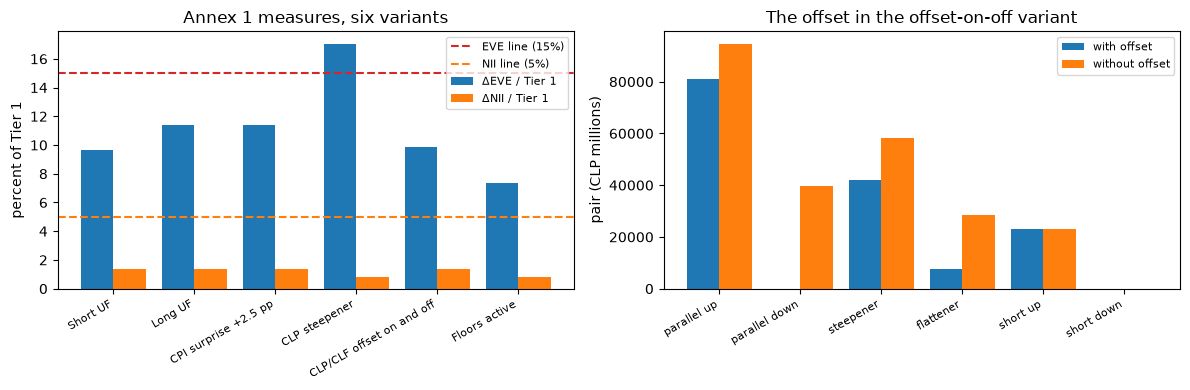

In [14]:
# Draw the two ratios of the six variants against their lines and the pair with and without the offset
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(ids))
left.bar(x - 0.2, [summary[v][0] * 100 for v in ids], 0.4, label="ΔEVE / Tier 1")
left.bar(x + 0.2, [summary[v][1] * 100 for v in ids], 0.4, label="ΔNII / Tier 1")
left.axhline(15, color="tab:red", linestyle="--", label="EVE line (15%)")
left.axhline(5, color="tab:orange", linestyle="--", label="NII line (5%)")
left.set_xticks(x)
left.set_xticklabels([variants[v]["outputs"]["variant"]["label"][LANG] for v in ids], rotation=30, ha="right", fontsize=8)
left.set_ylabel("percent of Tier 1")
left.set_title("Annex 1 measures, six variants")
left.legend(fontsize=8)
pairs = variants["offset-on-off"]["outputs"]["eve"]["rows"]
right.bar(np.arange(6) - 0.2, [r["pair"]["with_offset"] for r in pairs], 0.4, label="with offset")
right.bar(np.arange(6) + 0.2, [r["pair"]["without_offset"] for r in pairs], 0.4, label="without offset")
right.set_xticks(np.arange(6))
right.set_xticklabels([NAME[r["shock"]] for r in pairs], rotation=30, ha="right", fontsize=8)
right.set_ylabel("pair (CLP millions)")
right.set_title("The offset in the offset-on-off variant")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The two legs.** The peso leg has assets of 4,988,540 and liabilities of 3,917,062 (CLP millions), a net asset position of 1,071,478. The UR leg is tiny in its own unit, 65.89 and 71.94 million CLF, but at 40,877.73 pesos per UF its net position of -6.05 million CLF is -247,264 CLP millions, which is the -30 percent of Tier 1 the variant is built to have. That position, 30 percent of Tier 1 and not the size of the UF book, sets the charge.
- **The curves.** The engine rebuilds both Nelson-Siegel fits exactly: the peso curve with a decay of 1 year and an error of 0.50 bp, the UF curve with a decay of 2.5 years and 0.41 bp. At the shortest band the peso curve is at 4.50 percent and the UF curve at 1.21 percent, at 25 years at 5.91 and 2.84 percent: the nominal curve sits about 3 points above the real one, as the inflation compensation the market prices would imply. The peso curve rests on three market yields and the policy rate, so its shortest point is a policy rate and not a market one; a validator should read that as an open choice, not a measurement.
- **Caps and multipliers.** The retail operational segment asks for 95 percent and 5.5 years and is cut to 90 percent and 5 years, the wholesale one asks for 60 percent and 4.5 years and is cut to 50 percent and 4 years, and the retail non-operational one asks for exactly its caps and is not cut. The multipliers are those of Basel, repeated by the Annex: with a base prepayment of 5 percent, the parallel-up, steepener and short-up shocks give 4 percent and the other three 6 percent, and with a base early redemption of 5 percent the shocks parallel up, flattener and short up give 6 percent and the other three 4 percent.
- **The delta EVE.** In the short-UF variant both legs lose under the parallel-up shock (34,216 for the peso and 45,427 for the UR), which is the worst shock, so the pair is their sum, 79,643, and the offset does nothing. Where the legs go in opposite directions the offset acts: in the steepener the pair is 34,337 with it and 38,748 without, in the flattener 0 with it and 16,211 without. The Annex measure is the maximum over the six shocks, so the offset changes the measure only if it changes the worst shock, as the offset-on-off variant shows in the last figure. The delta EVE is 9.66 percent of Tier 1.
- **The delta NII and the charge.** The peso gains when rates rise (-7,059) and the UR loses (8,415): the pair with the offset is 4,885, against 8,415 without it. The charge is 6,182, 55.9 percent of the delta NII of 11,067: more than half of the NII measure is a function of the size of the net UF position, not of the shock. The charge is the same, 6,182, for a net short position of -247,264 and a net long one of +247,264, while a 2.5 point inflation surprise is a loss of 6,182 for the short bank and a gain of 6,182 (the committed effect is -6,182) for the long one: the standard charge is a one-sided add-on, the scenario is two-sided.
- **The tests.** The short-UF bank is at 1.34 percent of Tier 1 for the delta NII (line 5), at 9.66 percent for the delta EVE (line 15) and at 4.03 percent of the 12-month margin (line 18): not prioritised. Of the six variants only the peso steepener crosses a line, the delta EVE at 17.06 percent, and is prioritised; the long UF variant, at 11.38 percent, is the nearest of the others.
- **The floors.** No floor binds in any of the six variants. The closest post-shock rate is the UR rate of the first band under a 300 bp fall, at -1.795 percent against a floor of -2 percent, 20.48 bp away; the next are 50.21 bp (the peso, short-down), 70.65 and 120.48 bp. The `floors-active` variant, with 70 percent of the UF commercial loans floating, was built to bring the floors into play and does not: its name states the intent, not the result. With rates at today's levels the floor is a rule the engine implements and tests (notebook 02), not one that moves a number.
- **What the notebook does not show.** The dynamic NII and the Hull-White distributions of the two legs, the prices of the UF indexation itself (the real rate is on the curve, the inflation is in the charge), and any check of the Chilean figures against a second implementation: there is none to compare with (notebook 08).

## Summary

- The Chilean Annex treats the UF as one currency, the UR, with its own curve, its own shock sizes, a floor at -2 percent, and an indexation charge of 2.5 percent of the absolute net UF position; the engine reproduces each piece and never converts between currencies.
- The delta EVE takes the six shocks on each leg, pairs the legs with the 50 percent offset on the gain leg and takes the worst shock; the delta NII uses a single 300 bp shock, the same pairing and adds the charge once.
- The charge does not depend on the shock or on the sign of the position, so a net long UF bank, which gains from inflation, pays the same as a net short one.
- Three tests make a bank prioritised: the delta NII over 5 percent of Tier 1, the delta EVE over 15 percent, and the delta NII over 18 percent of the 12-month margin; one of the six variants crosses a line.
- No floor binds in any of the six variants; the closest post-shock rate is 20.48 bp from its floor, in the UR leg under a 300 bp fall.

**What to try next.** Change `net_uf_share_tier1` by choosing the `long-uf` variant as the main one in the first cell and read how the pair of the first shock changes. Then continue with notebook 07, the state of the art.

## References

- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1, Determinacion de la exposicion al riesgo de mercado en el libro de banca (Circular 2.270 of 2020 and 2.365 of 2025). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31 (the shocks, the bands, the caps and the multipliers, repeated by the Annex). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- CMF, Informe del Desempeno del Sistema Bancario y Cooperativas, August 2026, Cuadro N 1 (the aggregates of the synthetic bank). https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- Banco Central de Chile, Base de Datos Estadisticos, table F022 (secondary-market yields) and series F073.UFF.PRE.Z.D (the UF), terms of use. https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html
- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Dossier 03 of the Contraste research (Chile), section F.2.